## Model A — familiar sports

Train on Football, Basketball and Track; test on different athletes from those same sports. Compare a majority-class dummy, decision tree and random forest. Tune by **macro-F1**, keeping athletes together in every split.

### 2.1 Setup

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, classification_report,
                             ConfusionMatrixDisplay, f1_score)
from sklearn.model_selection import (train_test_split, StratifiedGroupKFold,
                                     cross_val_score, GridSearchCV, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier

SEED = 42
SPORTS = ['Football', 'Basketball', 'Track']
TARGET = 'injury_occurred'
LABELS = {0: 'Healthy', 1: 'Low Risk', 2: 'High Risk/Injured'}
SURFACES = {0: 'Grass', 1: 'Turf', 2: 'Indoor', 3: 'Track', 4: 'Other'}

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 20)
pd.set_option('display.max_colwidth', 100)

### 2.2 Load and prepare

Same light cleaning from 1_data, same 25 predictors, sport is reserved for splitting and reporting.

In [3]:
df = pd.read_csv('multimodal_sports_injury_dataset.csv')

# as in first notebook
for col in ['sport_type', 'gender']:
    df[col] = df[col].astype('string').str.strip()
df['sport_type'] = df['sport_type'].replace({'Soccer': 'Football'})
df = df.loc[df['sport_type'].isin(SPORTS)].copy()
df['playing_surface'] = df['playing_surface'].map(SURFACES).astype('category')
df['gender'] = df['gender'].astype('category')

X = df.drop(columns=['athlete_id', 'session_id', 'sport_type', TARGET])
y = df[TARGET]
print(f'{len(df):,} sessions, {df.athlete_id.nunique()} athletes, {X.shape[1]} predictors')

13,043 sessions, 132 athletes, 25 predictors


### 2.3 Athlete-level train/test split

I'll hold out 20% of athletes separately within each sport. Every session follows the athlete; I don't want any single athlete's sessions to be partly in test, partly in train.

In [4]:
athletes = df[['athlete_id', 'sport_type']].drop_duplicates().sort_values('athlete_id')
train_ids, test_ids = [], []
for sport in SPORTS:
    ids = athletes.loc[athletes['sport_type'].eq(sport), 'athlete_id']
    # Split athlete IDs, not individual sessions.
    train_part, test_part = train_test_split(ids, test_size=0.20, random_state=SEED)
    train_ids.extend(train_part)
    test_ids.extend(test_part)

assert set(train_ids).isdisjoint(test_ids), 'An athlete appears on both sides.' # isdisjoint() returns True if two sets have no elements in common

# a block for splitting based on athlete_id
train_mask = df['athlete_id'].isin(train_ids)
test_mask = df['athlete_id'].isin(test_ids)
X_train, X_test = X.loc[train_mask], X.loc[test_mask]
y_train, y_test = y.loc[train_mask], y.loc[test_mask]
groups_train = df.loc[train_mask, 'athlete_id']

# session indices stay aligned with the original data.
split_counts = df.assign(partition=np.where( # partition column to indicate whether the row belongs to the training or testing set
    train_mask, 'Train', 'Test')).groupby( # groupby() to group the DataFrame by sport_type and partition
    ['sport_type', 'partition']
).agg(athletes=('athlete_id', 'nunique'), sessions=('athlete_id', 'size')) # final aggregation to count the number of unique athletes and total sessions in each group

display(split_counts)

athletes  sessions
sport_type partition                    
Basketball Test              9       890
           Train            32      3169
Football   Test             10       989
           Train            39      3848
Track      Test              9       887
           Train            33      3260

### 2.4 Preprocessing

Nothing special: median imputation for numbers, most-frequent imputation and one-hot encoding for categories. Trees need no scaling. Each CV fold fits its own preprocessing.

In [5]:
categorical_features = ['playing_surface', 'gender']
numeric_features = [c for c in X.columns if c not in categorical_features]

# 2 types of processing
preprocessor = ColumnTransformer([
    ('numeric', SimpleImputer(strategy='median'), numeric_features),
    ('categorical', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('encode', OneHotEncoder(handle_unknown='ignore')),
    ]), categorical_features),
])

# every model will be wrapped in a pipeline with the preprocessor
def make_model(estimator):
    return Pipeline([('preprocess', clone(preprocessor)), ('model', estimator)])

### 2.5 Grouped CV

Use the same five folds for every model. Stratification approximately balances labels; grouping prevents an athlete crossing a fold boundary.

In [ ]:
# Balance labels while keeping each athlete together.
cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
# Reuse identical folds across all models.
folds = list(cv.split(X_train, y_train, groups=groups_train))
fold_rows = []
for fold, (train_idx, valid_idx) in enumerate(folds, start=1):
    # CV indices are positions within X_train, so iloc is used.
    fit_groups = groups_train.iloc[train_idx]
    valid_groups = groups_train.iloc[valid_idx]

    assert set(fit_groups).isdisjoint(valid_groups), 'An athlete crosses a CV fold.' # same set check

    valid_athletes = df.loc[X_train.iloc[valid_idx].index, ['athlete_id', 'sport_type']].drop_duplicates()
    counts = valid_athletes['sport_type'].value_counts().reindex(SPORTS, fill_value=0)
    fold_rows.append({'Fold': fold, 'Train athletes': fit_groups.nunique(),
                      'Validation athletes': valid_groups.nunique(), **counts.to_dict()})
    
display(pd.DataFrame(fold_rows).set_index('Fold'))

,Train athletes,Validation athletes,Football,Basketball,Track
Fold,,,,,
1,83,21,8,7,6
2,83,21,8,8,5
3,84,20,6,5,9
4,83,21,9,5,7
5,83,21,8,7,6


### 2.6 Dummy baseline

Always predict the most frequent training class. This gives a reference without learning feature relationships.

In [6]:
dummy = make_model(DummyClassifier(strategy='most_frequent'))
dummy_cv = cross_val_score(dummy, X_train, y_train, cv=folds, scoring='f1_macro', n_jobs=2)
dummy.fit(X_train, y_train)
print(f'Dummy CV macro-F1: {dummy_cv.mean():.3f} ± {dummy_cv.std():.3f}')

Dummy CV macro-F1: 0.260 ± 0.001


### 2.7 Decision tree

Trying 18 combinations of depth, leaf size and class weighting. Depth and leaf size control overfitting.

In [7]:
tree_grid = {
    'model__max_depth': [3, 6, None],
    'model__min_samples_leaf': [5, 20, 50],
    'model__class_weight': [None, 'balanced'],
}
tree_search = GridSearchCV(
    make_model(DecisionTreeClassifier(random_state=SEED)), tree_grid,
    cv=folds, scoring='f1_macro', n_jobs=2, pre_dispatch=2, error_score='raise',
)
tree_search.fit(X_train, y_train)
print('Best tree settings:', tree_search.best_params_)
print(f'Best CV macro-F1: {tree_search.best_score_:.3f}')

Best tree settings: {'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 5}
Best CV macro-F1: 0.444


### 2.8 Random forest

Fix 200 trees and sample 12 settings for depth, leaf size, feature sampling and class weighting. Limit parallel work to two CV fits at a time.

In [8]:
forest_grid = {
    'model__max_depth': [6, 12, None],
    'model__min_samples_leaf': [2, 10, 30],
    'model__max_features': ['sqrt', 0.5],
    'model__class_weight': [None, 'balanced'],
}
forest_search = RandomizedSearchCV(
    make_model(RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=1)),
    forest_grid, n_iter=12, random_state=SEED,
    cv=folds, scoring='f1_macro', n_jobs=2, pre_dispatch=2, error_score='raise',
)
forest_search.fit(X_train, y_train)
print('Best forest settings:', forest_search.best_params_)
print(f'Best CV macro-F1: {forest_search.best_score_:.3f}')

Best forest settings: {'model__min_samples_leaf': 30, 'model__max_features': 0.5, 'model__max_depth': None, 'model__class_weight': 'balanced'}
Best CV macro-F1: 0.465


### 2.9 Training and CV comparison

Choose settings using CV only. Search objects already refit their best pipeline on all training athletes. CV standard deviations describe fold variation, not confidence intervals.

In [9]:
models = {'Dummy': dummy, 'Decision tree': tree_search.best_estimator_,
          'Random forest': forest_search.best_estimator_}
cv_rows = [{'Model': 'Dummy', 'CV macro-F1': dummy_cv.mean(), 'CV std': dummy_cv.std()}]
for name, search in [('Decision tree', tree_search), ('Random forest', forest_search)]:
    best = search.best_index_
    cv_rows.append({'Model': name, 'CV macro-F1': search.best_score_,
                    'CV std': search.cv_results_['std_test_score'][best]})
cv_comparison = pd.DataFrame(cv_rows).set_index('Model')
cv_comparison['Train macro-F1'] = [
    f1_score(y_train, model.predict(X_train), average='macro', zero_division=0)
    for model in models.values()
]
display(cv_comparison.round(3))

# Retain all tried settings inline, ordered by their CV score.
for name, search in [('Decision tree', tree_search), ('Random forest', forest_search)]:
    print(name, '— top five CV settings')
    trials = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
    display(trials[['mean_test_score', 'std_test_score', 'params']].head().round(3))

,CV macro-F1,CV std,Train macro-F1
Model,,,
Dummy,0.260,0.001,0.260
Decision tree,0.444,0.010,0.814
Random forest,0.465,0.007,0.743


Decision tree — top five CV settings


,mean_test_score,std_test_score,params
6,0.444,0.010,"{'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 5}"
15,0.437,0.010,"{'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 5}"
7,0.436,0.009,"{'model__class_weight': None, 'model__max_depth': None, 'model__min_samples_leaf': 20}"
17,0.434,0.007,"{'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 50}"
16,0.429,0.005,"{'model__class_weight': 'balanced', 'model__max_depth': None, 'model__min_samples_leaf': 20}"


Random forest — top five CV settings


,mean_test_score,std_test_score,params
0,0.465,0.007,"{'model__min_samples_leaf': 30, 'model__max_features': 0.5, 'model__max_depth': None, 'model__cl..."
2,0.459,0.004,"{'model__min_samples_leaf': 30, 'model__max_features': 'sqrt', 'model__max_depth': 12, 'model__c..."
11,0.452,0.012,"{'model__min_samples_leaf': 10, 'model__max_features': 0.5, 'model__max_depth': None, 'model__cl..."
6,0.452,0.009,"{'model__min_samples_leaf': 2, 'model__max_features': 0.5, 'model__max_depth': 6, 'model__class_..."
5,0.450,0.006,"{'model__min_samples_leaf': 10, 'model__max_features': 'sqrt', 'model__max_depth': None, 'model_..."


### 2.10 Held-out test results

Evaluate the frozen pipelines. Macro-F1 weights classes equally; balanced accuracy averages their recalls. Accuracy is included for context.

In [10]:
def scores(actual, predicted):
    return {'Macro-F1': f1_score(actual, predicted, labels=list(LABELS),
                                average='macro', zero_division=0),
            # Balanced accuracy averages recall across classes.
            'Balanced accuracy': balanced_accuracy_score(actual, predicted),
            'Accuracy': accuracy_score(actual, predicted)}

# Keep athlete IDs for the later matched comparison with B–D.
test_predictions = df.loc[test_mask, ['athlete_id', 'sport_type', TARGET]].copy()
test_rows = []
for name, model in models.items():
    predicted = model.predict(X_test)
    test_predictions[name] = predicted
    test_rows.append({'Model': name, **scores(y_test, predicted)})
test_results = pd.DataFrame(test_rows).set_index('Model')
display(test_results.round(3))

,Macro-F1,Balanced accuracy,Accuracy
Model,,,
Dummy,0.259,0.333,0.634
Decision tree,0.447,0.442,0.549
Random forest,0.469,0.543,0.564


### 2.11 Results by sport

These are Model A’s familiar-sport references for B–D. Later transfer models can also be scored on these same target athletes.

In [11]:
sport_rows = []
for sport in SPORTS:
    subset = test_predictions.loc[test_predictions['sport_type'].eq(sport)]
    for name in models:
        sport_rows.append({'Sport': sport, 'Model': name,
                           'Athletes': subset['athlete_id'].nunique(), 'Sessions': len(subset),
                           **scores(subset[TARGET], subset[name])})
sport_results = pd.DataFrame(sport_rows).set_index(['Sport', 'Model'])
display(sport_results.round(3))

Athletes  Sessions  Macro-F1  Balanced accuracy  \
Sport      Model                                                            
Football   Dummy                10       989     0.259              0.333   
           Decision tree        10       989     0.453              0.450   
           Random forest        10       989     0.455              0.534   
Basketball Dummy                 9       890     0.259              0.333   
           Decision tree         9       890     0.454              0.445   
           Random forest         9       890     0.461              0.527   
Track      Dummy                 9       887     0.259              0.333   
           Decision tree         9       887     0.428              0.426   
           Random forest         9       887     0.492              0.566   

                          Accuracy  
Sport      Model                    
Football   Dummy             0.634  
           Decision tree     0.561  
           Random forest     0.549  
Basketball Dummy             0.634  
           Decision tree     0.553  
           Random forest     0.557  
Track      Dummy             0.635  
           Decision tree     0.532  
           Random forest     0.589

### 2.12 Errors by class

Rows are actual labels; columns are predictions. Normalize within each actual class to compare recall.

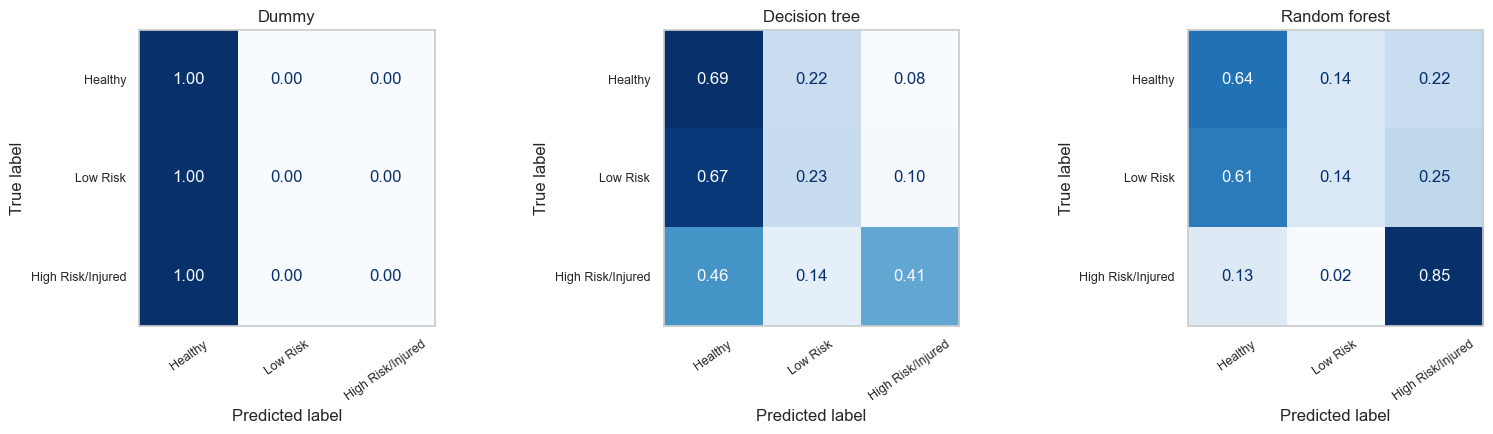

precision  recall  f1-score  support
Model         Class                                                  
Dummy         Healthy                0.634   1.000     0.776   1754.0
              Low Risk               0.000   0.000     0.000    595.0
              High Risk/Injured      0.000   0.000     0.000    417.0
Decision tree Healthy                0.672   0.692     0.682   1754.0
              Low Risk               0.233   0.230     0.232    595.0
              High Risk/Injured      0.451   0.405     0.427    417.0
Random forest Healthy                0.730   0.640     0.682   1754.0
              Low Risk               0.244   0.143     0.180    595.0
              High Risk/Injured      0.402   0.847     0.545    417.0

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for (name, model), ax in zip(models.items(), axes):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_predictions[name], labels=list(LABELS), display_labels=list(LABELS.values()),
        # Show proportions within each actual class.
        normalize='true', values_format='.2f', cmap='Blues', colorbar=False, ax=ax,
    )
    ax.set_title(name)
    ax.tick_params(axis='x', labelrotation=35, labelsize=9)
    ax.tick_params(axis='y', labelsize=9)
    ax.grid(False)
fig.tight_layout()
plt.show()

reports = {}
for name in models:
    report = classification_report(
        y_test, test_predictions[name], labels=list(LABELS), target_names=list(LABELS.values()),
        output_dict=True, zero_division=0,
    )
    reports[name] = pd.DataFrame(report).T.loc[list(LABELS.values()),
                                              ['precision', 'recall', 'f1-score', 'support']]
display(pd.concat(reports, names=['Model', 'Class']).round(3))

### Interpretation

- Test macro-F1: dummy **0.259**, tree **0.447**, forest **0.469**. CV also favored the forest.
- Dummy accuracy is higher (0.634), but it misses both risk classes entirely.
- Forest High Risk/Injured recall is **0.847**, with precision **0.402**; Low Risk recall is only **0.143**.
- Both learned models have substantial training–CV gaps, suggesting overfitting.

These are session risk/status results from 28 held-out athletes. Collection and labeling limitations still apply. Keep these settings frozen for comparison; no files or figures are exported.

**Next:** [Model A, version 2](3_model_A_binary.ipynb) merges Healthy + Low Risk into **Not high risk**, keeping **High Risk/Injured** positive. We prioritize recall using F2 and training-only cutoff selection, and compare models with and without sport. The athlete split stays the same; this is an exploratory revision prompted by these results.